# R3 - Behavioral summary and published reference

Select `.venv`, Restart Kernel, then Run All. This step reads the release
preprocessing log; it does not load or clean the EEG files.

Keep two overlapping cohorts separate: the 39 subjects remaining after
the paper-based a-priori exclusions, and the 35 subjects retained for ERP.
References are the published mean/SD values in Dzianok et al., Table 5,
stored in `erp.behaviour_reference`. See the behavior section in `reports/r3_review_and_handoff.md`.


In [1]:
import hashlib
import json
import sys

import matplotlib.pyplot as plt
from IPython.display import display

from eegproj.config import find_root, load_config
from eegproj.evaluation.behaviour_summary import (
    load_behaviour_subjects,
    plot_behaviour_comparison,
    summarise_behaviour,
)

ROOT = find_root()
CONFIG = load_config(ROOT)
REFERENCE = CONFIG["erp"]["behaviour_reference"]
LOG_PATH = ROOT / CONFIG["paths"]["derivatives"] / "preproc_log.csv"
OUTPUT_DIR = ROOT / "results" / "erp"
FIGURE_DIR = ROOT / CONFIG["paths"]["figures"]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", sys.executable)
print("Input log:", LOG_PATH)
print("Paper reference:", REFERENCE["source_url"], "Table", REFERENCE["source_table"])

Python: /home/tbm/miniconda3/envs/big_env/bin/python
Input log: /home/tbm/Documents/EEG_26_27/data/derivatives/preproc/preproc_log.csv
Paper reference: https://academic.oup.com/gigascience/article/doi/10.1093/gigascience/giac015/6543635 Table 5


## 1. Check original behavioral counts and cohort membership

Rates use total stimuli and behaviorally correct trials before EEG epoch
rejection. Do not calculate hit rate from retained target epochs: that
would mix task performance with signal quality. Use each person's actual
trial counts, including recordings with counts that differ from the design.


In [2]:
subjects, exclusions = load_behaviour_subjects(ROOT, CONFIG)
print("Before EEG QC, after a-priori exclusions:", len(subjects))
print("ERP cohort:", int(subjects["in_erp_cohort"].sum()))
display(
    subjects[
        [
            "subject",
            "in_erp_cohort",
            "hit_rate_pct",
            "target_omission_pct",
            "false_alarm_standard_pct",
            "false_alarm_distractor_pct",
            "rt_mean_ms",
        ]
    ]
)
display(exclusions)

Before EEG QC, after a-priori exclusions: 39
ERP cohort: 35


,subject,in_erp_cohort,hit_rate_pct,target_omission_pct,false_alarm_standard_pct,false_alarm_distractor_pct,rt_mean_ms
0,sub-01,True,76.543210,23.456790,2.610442,35.802469,571.532258
1,sub-03,True,100.000000,0.000000,0.200803,12.345679,507.716049
2,sub-04,True,97.530864,2.469136,0.000000,6.172840,552.911392
3,sub-05,True,100.000000,0.000000,0.000000,9.876543,428.567901
4,sub-06,True,96.296296,3.703704,0.200803,3.703704,579.602564
5,sub-07,True,60.493827,39.506173,1.004016,29.629630,686.387755
6,sub-08,False,85.185185,14.814815,0.401606,14.814815,561.260870
7,sub-09,True,87.654321,12.345679,0.000000,8.641975,592.169014
8,sub-10,True,82.716049,17.283951,0.803213,38.271605,545.761194
9,sub-11,True,100.000000,0.000000,0.000000,1.234568,417.555556


,subject,exclusion_reason,stage
0,sub-02,paper: false alarms to distractors 98.8% (misu...,a_priori
1,sub-08,target_retention_below_threshold,eeg_or_target_criteria
2,sub-14,paper: false alarms to distractors 97.5% (misu...,a_priori
3,sub-17,paper: false alarms to distractors 76.5% (misu...,a_priori
4,sub-23,target_retention_below_threshold,eeg_or_target_criteria
5,sub-35,target_retention_below_threshold,eeg_or_target_criteria
6,sub-41,target_retention_below_threshold,eeg_or_target_criteria


## 2. Subject-level mean and sample SD

Average per-subject percentages and RT means with equal subject weights.
The group RT SD is the sample SD of `rt_mean_ms` across subjects; it is
not the mean of `rt_sd_ms`, which describes within-subject RT variability.
The two cohorts overlap, so this is a descriptive comparison, not a
statistical test between independent samples.


In [3]:
summary = summarise_behaviour(subjects, CONFIG)
compact = summary[
    [
        "cohort",
        "metric",
        "n_subjects",
        "mean",
        "sd",
        "paper_mean",
        "paper_sd",
        "mean_difference_from_paper",
        "difference_unit",
    ]
]
display(compact)
comparison = summary.copy()
comparison["local_mean_sd"] = comparison.apply(lambda row: f"{row['mean']:.2f} +/- {row['sd']:.2f}", axis=1)
comparison["paper_mean_sd"] = comparison.apply(lambda row: f"{row['paper_mean']:.2f} +/- {row['paper_sd']:.2f}", axis=1)
display(
    comparison[
        [
            "cohort",
            "label",
            "n_subjects",
            "local_mean_sd",
            "paper_n_subjects",
            "paper_mean_sd",
            "mean_difference_from_paper",
            "difference_unit",
        ]
    ]
)

,cohort,metric,n_subjects,mean,sd,paper_mean,paper_sd,mean_difference_from_paper,difference_unit
0,before_eeg_qc,rt_mean_ms,39,542.132972,65.503170,542.13,65.50,0.002972,ms
1,before_eeg_qc,hit_rate_pct,39,94.372667,8.458805,94.40,8.33,-0.027333,percentage_points
2,before_eeg_qc,target_omission_pct,39,5.627333,8.458805,5.60,8.33,0.027333,percentage_points
3,before_eeg_qc,false_alarm_distractor_pct,39,9.535001,9.050109,9.52,8.90,0.015001,percentage_points
4,before_eeg_qc,false_alarm_standard_pct,39,0.236104,0.467324,0.24,0.46,-0.003896,percentage_points
5,erp_usable,rt_mean_ms,35,543.792932,61.329859,542.13,65.50,1.662932,ms
6,erp_usable,hit_rate_pct,35,94.391534,8.751986,94.40,8.33,-0.008466,percentage_points
7,erp_usable,target_omission_pct,35,5.608466,8.751986,5.60,8.33,0.008466,percentage_points
8,erp_usable,false_alarm_distractor_pct,35,9.126984,9.365550,9.52,8.90,-0.393016,percentage_points
9,erp_usable,false_alarm_standard_pct,35,0.245876,0.489761,0.24,0.46,0.005876,percentage_points


,cohort,label,n_subjects,local_mean_sd,paper_n_subjects,paper_mean_sd,mean_difference_from_paper,difference_unit
0,before_eeg_qc,Target reaction time,39,542.13 +/- 65.50,39,542.13 +/- 65.50,0.002972,ms
1,before_eeg_qc,Target hit rate,39,94.37 +/- 8.46,39,94.40 +/- 8.33,-0.027333,percentage_points
2,before_eeg_qc,Target omission,39,5.63 +/- 8.46,39,5.60 +/- 8.33,0.027333,percentage_points
3,before_eeg_qc,Distractor false alarm,39,9.54 +/- 9.05,39,9.52 +/- 8.90,0.015001,percentage_points
4,before_eeg_qc,Standard false alarm,39,0.24 +/- 0.47,39,0.24 +/- 0.46,-0.003896,percentage_points
5,erp_usable,Target reaction time,35,543.79 +/- 61.33,39,542.13 +/- 65.50,1.662932,ms
6,erp_usable,Target hit rate,35,94.39 +/- 8.75,39,94.40 +/- 8.33,-0.008466,percentage_points
7,erp_usable,Target omission,35,5.61 +/- 8.75,39,5.60 +/- 8.33,0.008466,percentage_points
8,erp_usable,Distractor false alarm,35,9.13 +/- 9.37,39,9.52 +/- 8.90,-0.393016,percentage_points
9,erp_usable,Standard false alarm,35,0.25 +/- 0.49,39,0.24 +/- 0.46,0.005876,percentage_points


## 3. Save tables and provenance

Keep the pre-EEG-QC and ERP cohort labels in exported summaries. Hit rate
in the paper reference is derived from 100% minus published omission;
that derivation is marked in the table. Preserve observed differences
from published results without forcing an exact match or inventing causes.


In [4]:
subjects.to_csv(OUTPUT_DIR / "behaviour_subjects.csv", index=False)
exclusions.to_csv(OUTPUT_DIR / "behaviour_exclusions.csv", index=False)
summary.to_csv(OUTPUT_DIR / "behaviour_summary.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "behaviour_vs_paper.csv", index=False)
manifest = {
    "pipeline_version": 2,
    "input_log": str(LOG_PATH.relative_to(ROOT)),
    "input_log_sha256": hashlib.sha256(LOG_PATH.read_bytes()).hexdigest(),
    "subjects_before_eeg_qc": subjects["subject"].tolist(),
    "subjects_erp_usable": subjects.loc[subjects["in_erp_cohort"], "subject"].tolist(),
    "n_before_eeg_qc": len(subjects),
    "n_erp_usable": int(subjects["in_erp_cohort"].sum()),
    "aggregation": "equal-weight subject means and sample SD (ddof=1)",
    "rate_denominator": "original stimulus counts before EEG epoch rejection",
    "rt_sd": "sample SD across per-subject mean RTs, not mean within-subject RT SD",
    "reference": REFERENCE,
    "comparison": "descriptive; cohorts overlap; no significance tests or exact-replication claims",
    "signal_qc_status": subjects.loc[subjects["in_erp_cohort"], "visual_review"].value_counts().to_dict(),
}
(OUTPUT_DIR / "behaviour_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved tables and manifest:", OUTPUT_DIR)

Saved tables and manifest: /home/tbm/Documents/EEG_26_27/results/erp


## 4. Plot subjects and published mean +/- SD

Gray dots show observed participants. Diamonds/error bars show mean and
between-subject SD. Paper individual observations are unavailable here;
only its reported mean/SD are plotted. SD bars are not confidence intervals
and can extend beyond the valid range of a rate. The two local cohorts
share subjects and must not be treated as independent groups.


Saved: /home/tbm/Documents/EEG_26_27/figures/R3_behaviour_comparison.png
Saved: /home/tbm/Documents/EEG_26_27/figures/R3_behaviour_comparison.pdf


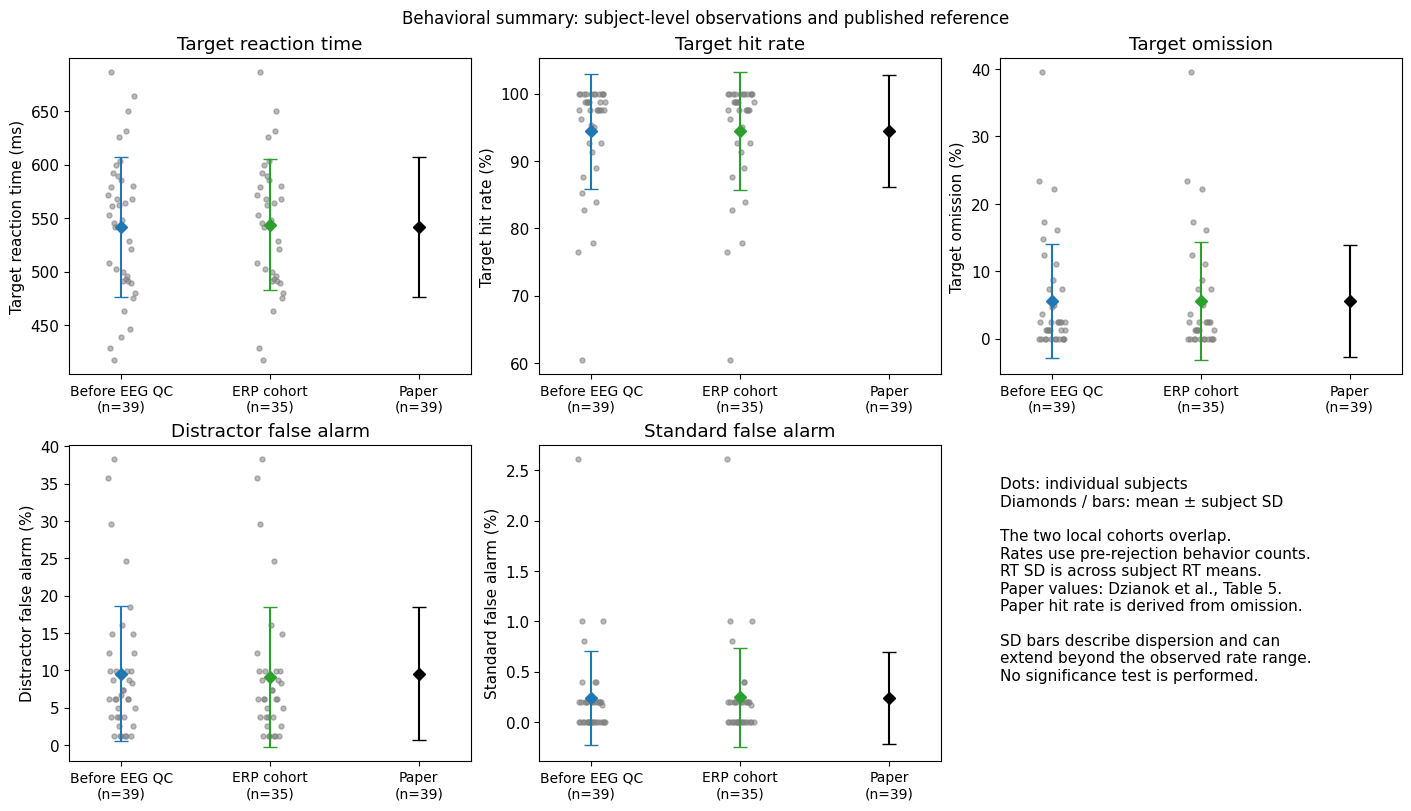

In [5]:
fig = plot_behaviour_comparison(subjects, summary, CONFIG)
for suffix in ("png", "pdf"):
    path = FIGURE_DIR / f"R3_behaviour_comparison.{suffix}"
    fig.savefig(path, dpi=CONFIG["erp"]["figure_dpi"], bbox_inches="tight")
    print("Saved:", path)
plt.show()

## Next step

Use the ERP cohort's behavioral summary when describing the final ERP
sample. Keep the pre-EEG-QC summary when comparing selection rules with
the paper. Review the flagged P300 candidates with the team and coordinate
signal QC with R2 before finalizing report results.

Remaining R3 tasks include the ERP report text, QC illustrations supplied
by R2, and F3 performance aggregation once R4/R5 provide their metric CSVs.
Generated CSV/JSON/figure outputs are saved in ignored directories.
